# Da planilha ao script: análise reprodutível com R
**Aula-amostra · Workshop "Pesquisa reprodutível na prática"**

### O problema
Uma análise feita clicando numa planilha ou num programa como o Prism pode ser refeita, mas a um custo alto: é preciso reconstruir, a partir de anotações e arquivos, o que foi copiado, excluído, rearranjado e testado. É uma espécie de engenharia reversa, e nada garante que o caminho seguido seja o mesmo.

No código, isso não acontece: o código é, ao mesmo tempo, **instrução e documentação**. O que está escrito é exatamente o que foi executado, e refazer a análise é rodar de novo.

### As ferramentas
Esta aula usa um **notebook Jupyter** (arquivo `.ipynb`), um documento que intercala **células de texto**, como esta, com **células de código**, cujos resultados (tabelas, gráficos, testes) aparecem logo abaixo e ficam salvos no próprio arquivo. Por isso o notebook serve, ao mesmo tempo, como análise e como relatório. Ele pode ser exportado como HTML, PDF ou script, e o próprio GitHub mostra notebooks já formatados.

Para rodar o notebook, usamos o **Google Colab**, que executa tudo na nuvem, pelo navegador: não é preciso instalar nada nem processar nada no próprio computador, basta uma conta Google. O mesmo notebook também roda no **Binder** (sem conta, a partir do repositório) ou no computador de cada um, com o R e o Jupyter instalados.

## 1. Os dados e o plano de análise
**Dados (simulados, criados para o workshop):** pressão arterial sistólica (mmHg) de 60 ratos hipertensos, tratados com um de dois fármacos (`A` ou `B`) em uma de três doses (1, 3 ou 10 mg/kg), com 10 animais por grupo.

**Plano de análise:**
- **Pergunta principal (confirmatória):** na dose de 1 mg/kg, a pressão arterial sistólica média difere entre os fármacos A e B?
- **Teste:** t de Welch, bilateral, com nível de significância de 5%, relatando a diferença entre as médias com intervalo de confiança de 95%.
- **Qualquer análise fora deste plano** será relatada como **exploratória**.

> Num estudo real, este plano seria definido e registrado publicamente antes da coleta dos dados (por exemplo, no OSF). Aqui, com dados simulados, ele serve de modelo.

## 2. Ler os dados como eles chegam
Os dados estão depositados no **Zenodo**, um repositório de dados de pesquisa, com DOI e licença próprios ([10.5281/zenodo.24328555](https://doi.org/10.5281/zenodo.24328555)).

In [79]:
# comentário: tudo o que vem depois de # numa linha é ignorado pelo r e serve só para quem lê o código
library(readr)    # ler arquivos
library(dplyr)    # manipular dados
library(tidyr)    # manipular dados
library(ggplot2)  # gráficos

In [80]:
# Consulta à documentação da função - ?nome_da_funcao
?read_csv

In [81]:
# read_csv aceita uma url
# Não precisamos baixar o arquivo do zenodo. Basta a url para ele
# A seta <- guarda o resultado em um objeto chamado "pressao"
url_dados <- "https://zenodo.org/records/24328555/files/pressao_largo.csv?download=1"

In [82]:
# Podemos acessar o valor do objeto ao chamá-lo pelo nome
url_dados

[1] "https://zenodo.org/records/24328555/files/pressao_largo.csv?download=1"

In [83]:
# Importando os dados para dentro do R
pressao <- read_csv(url_dados)

Rows: 10 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (6): A_1, A_3, A_10, B_1, B_3, B_10

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [84]:
pressao

A_1,A_3,A_10,B_1,B_3,B_10
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
170,174,149,199,167,148
178,164,148,186,166,138
168,154,142,190,174,147
190,140,123,187,173,134
179,170,147,175,162,157
169,160,140,183,162,162
180,160,140,183,171,141
183,168,128,186,175,135
181,167,137,197,167,149


> **Pergunta para a turma:** relembrando a oficina de organização de projetos, estes dados estão **arrumados** (*tidy*)?

<details>
<summary><b>Resposta</b> (clique para abrir)</summary>

**Não.** Num conjunto de dados arrumado, cada variável é uma coluna e cada observação é uma linha. Aqui, duas variáveis, o fármaco (`A`, `B`) e a dose (`1`, `3`, `10`), estão escondidas nos **nomes das colunas**, e cada linha não corresponde a um animal: são seis animais diferentes, um em cada coluna.

</details>

## 3. Preparar os dados para a análise
Arrumar a tabela à mão, copiando e colando, funciona, mas não deixa registro e abre espaço para erros. Com código, são três passos, encadeados pelo **pipe** (`|>` ou `%>%`), que entrega o resultado de um passo como entrada do passo seguinte (leia como "e então"):
1. `pivot_longer()`: empilha as seis colunas numa só (`pas`: pressão arterial sistólica), guardando o nome de cada coluna de origem;
2. `separate_wider_delim()`: separa esse nome em fármaco e dose;
3. `mutate()`: transforma a dose em número.

In [85]:
pressao_tidy <- pressao |>
  pivot_longer(everything(), names_to = "grupo", values_to = "pas") |>
  separate_wider_delim(grupo, delim = "_", names = c("farmaco", "dose")) |>
  mutate(dose = as.numeric(dose))

In [86]:
pressao_tidy

farmaco,dose,pas
<chr>,<dbl>,<dbl>
A,1,170
A,3,174
A,10,149
B,1,199
B,3,167
B,10,148
A,1,178
A,3,164
A,10,148


Agora há uma linha por animal (60) e uma coluna por variável (`farmaco`, `dose`, `pas`). A tabela original não foi alterada, e cada passo da transformação está registrado no código.

## 4. Resumir por grupo com o `dplyr`
Com os dados arrumados, cada pergunta vira uma sequência de verbos: agrupar por fármaco e dose (`group_by()`), e então resumir cada grupo (`summarise()`) com o número de animais, a média e o desvio-padrão.

In [88]:
pressao_tidy |>
  group_by(farmaco, dose) |>          # um grupo para cada combinação de fármaco e dose
  summarise(                          # calcula, para cada grupo:
    n = n(),                          #   o número de animais
    media = mean(pas),                #   a média da pressão
    desvio_pd = sd(pas),              #   o desvio-padrão da pressão
    .groups = "drop"                  # devolve uma tabela comum, sem os grupos
  )

farmaco,dose,n,media,desvio_pd
<chr>,<dbl>,<int>,<dbl>,<dbl>
A,1,10,177.1,7.030884
A,3,10,162.2,9.647107
A,10,10,139.9,8.595218
B,1,10,188.0,7.226494
B,3,10,169.3,5.207900
B,10,10,145.4,9.131143


## 5. Olhar os dados antes de testar
No `ggplot2`, um gráfico é montado em partes, somadas com `+`:
1. **dados e mapeamentos estéticos** (`aes()`): qual variável vai para o eixo x, qual vai para o y e qual define a cor;
2. **camadas**, cada uma com uma forma geométrica (*geom*): aqui, caixas (`geom_boxplot()`) e um ponto para cada animal (`geom_point()`);
3. **ajustes** de rótulos (`labs()`) e aparência (`theme_minimal()`).

Mostrar os pontos individuais, e não só as caixas, deixa visível cada animal: com 10 por grupo, dá para ver toda a variação.

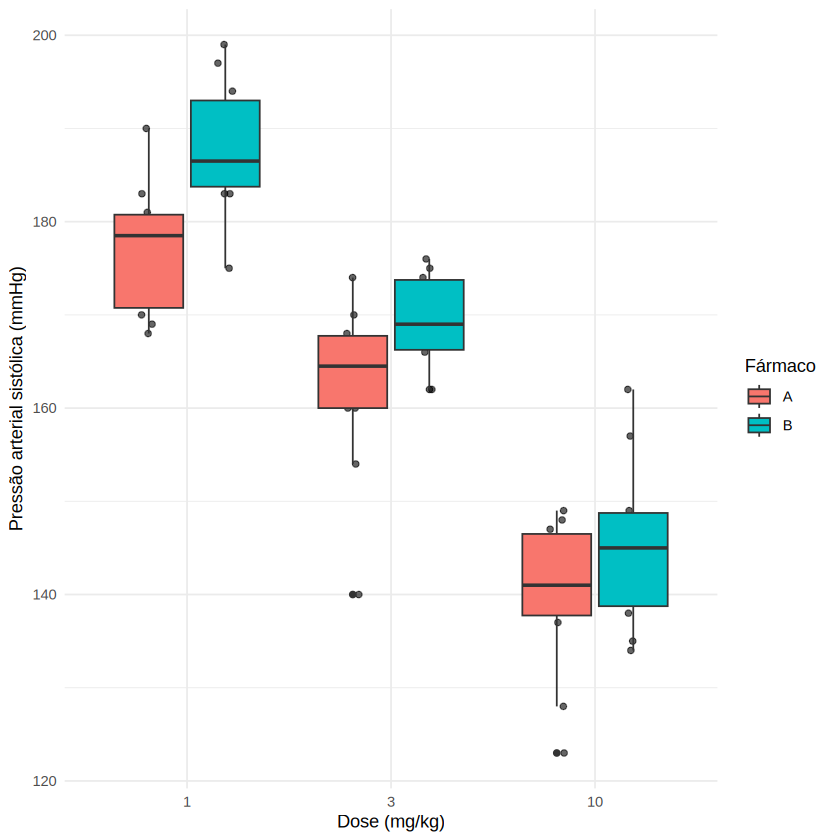

In [90]:
ggplot(pressao_tidy, aes(x = factor(dose), y = pas, fill = farmaco)) +   # dados e mapeamentos
  geom_boxplot() +                                                  # camada 1: boxplot
  geom_point(position = position_jitterdodge(jitter.width = 0.15),  # camada 2: um ponto por animal
             alpha = 0.6) +
  labs(x = "Dose (mg/kg)", y = "Pressão arterial sistólica (mmHg)",
       fill = "Fármaco") +                                          # rótulos
  theme_minimal()                                                   # aparência (minimal, classic, dark, light...)

## 6. Testar uma pergunta definida antes
**Na dose de 1 mg/kg, a pressão arterial média difere entre os fármacos?** Teste t de Welch para dois grupos independentes.

In [ ]:
pressao_tidy |>
  filter(dose == 1) |> # Filtre apenas tratamentos com dose 1 mg/kg
  t.test(pas ~ farmaco, data = _) # Compare a pressão entre os fármacos

Como definido no plano, relatamos a **diferença entre as médias e o seu intervalo de confiança**, não só o valor de p:

*Na dose de 1 mg/kg, a pressão média com o fármaco A foi cerca de 11 mmHg menor que com o fármaco B (IC 95%: 4 a 18 mmHg; p = 0,003).*

> **Pergunta para a turma:** o teste na dose de 10 mg/kg não estava no plano. Esse resultado poderia ser relatado da mesma forma que o da pergunta principal?

<details>
<summary><b>Resposta</b> (clique para abrir)</summary>

**Não.** Essa comparação não estava no plano: é uma **análise exploratória**. Ela pode sugerir hipóteses para um próximo estudo, mas não as confirma. Cada teste a mais aumenta a chance de um resultado "significativo" por acaso.

Se a pergunta também interessa nas outras doses, o caminho é **incluir essas comparações no plano desde o início** e **corrigir para comparações múltiplas** (por exemplo, pelo método de Holm).

Entretanto, a exploração também tem seu valor. No gráfico e nos resumos por grupo, a diferença entre A e B parece diminuir conforme a dose aumenta (cerca de 11, 7 e 5,5 mmHg). Isso não é uma conclusão, e sim uma **hipótese**, para ser testada num novo estudo, com um plano próprio: os mesmos dados não podem, ao mesmo tempo, sugerir uma hipótese e confirmá-la.

</details>

## 7. O teste de reprodutibilidade

**Reiniciar e executar tudo**. Se o notebook roda do início ao fim numa sessão limpa e dá os mesmos resultados, ele é reprodutível.

Por fim, registramos a versão do R e dos pacotes usados. Ao compartilhar o notebook, em HTML por exemplo, quem o receber sabe exatamente em que ambiente os resultados foram obtidos, e pode recriá-lo se precisar.

In [91]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] readxl_1.6.0  ggplot2_4.0.3 tidyr_1.3.2   dplyr_1.2.1   readr_2.2.0  

loaded via a namespace (and not attached):
 [1] bit_4.6.0          gtable_0.3.6       jsonlite_2.0.0    

## 8. Prática: a planilha do dia 1, agora por código
Ontem, vocês arrumaram à mão a planilha do teste de tolerância à glicose (`gtt_simulado.xlsx`, com dados simulados).


1. **Ler:** subam o arquivo no Colab (ícone de pasta, à esquerda) e leiam com `read_excel()`, do pacote `readxl`.
2. **Arrumar:** deixem os dados no formato tidy, com uma linha por medida e as colunas `animal`, `dieta`, `sexo`, `tempo_min` e `glicemia`.
3. **Registrar as decisões:** se algum dado for excluído ou corrigido, façam isso no código, com um comentário explicando o motivo.
4. **Salvar e baixar:** salvem a tabela arrumada em CSV com `write_csv()` e baixem o arquivo pelo painel de arquivos (três pontinhos ao lado do nome → Baixar). No próximo bloco, ele vai para o Zenodo Sandbox, junto com o dicionário de dados.
5. **Explorar:** respondam às perguntas abaixo, cada uma com poucas linhas de código.
   - Quantos animais há em cada combinação de dieta e sexo? (`count()`)
   - Quais são as combinações de dieta e sexo presentes nos dados, sem repetição? (`distinct()`)
   - Qual animal teve a maior glicemia, e em que tempo? (`arrange()`)
   - Qual é a glicemia média de cada dieta em cada tempo, **sem o animal excluído**? (`filter()`, `group_by()` e `summarise()`)
   - Montem uma tabela só com as colunas `animal`, `tempo_min` e `glicemia`. (`select()`)

**Desafios, para quem terminar antes:**
- Comparem, **por código**, o resultado com a versão que vocês arrumaram à mão ontem: leiam a versão manual e usem `anti_join()` para encontrar as linhas que aparecem numa tabela e não na outra. As colunas precisam ter os mesmos nomes nas duas (se não tiverem, vejam `?rename`). Bateu?
- Façam um gráfico da glicemia média ao longo do tempo, com uma linha para cada combinação de dieta e sexo.

**Usem a documentação.** O `dplyr` e o `tidyr` têm muitos outros verbos além dos que vimos. Antes de pedir ajuda, consultem `?nome_da_funcao`: a documentação explica cada argumento e termina com exemplos que podem ser copiados e adaptados.


<details>
<summary><b>Dicas</b> (clique para abrir)</summary>

- A planilha tem linhas de título antes do cabeçalho: procurem em `?read_excel` o argumento que pula linhas.
- Para arrumar: `pivot_longer()` empilha colunas, `separate_wider_delim()` separa uma coluna em duas, `filter()` remove linhas e `mutate()` cria ou transforma colunas.
- Para transformar textos como "15 min" em número: `?parse_number`.
- Para o gráfico: `?geom_line`.

</details>

In [ ]:
# ATIVIDADE 1

library(readxl)   # ler planilhas do Excel

gtt <- read_excel("gtt_simulado.xlsx")
gtt

# Continuem a partir daqui

## No próximo bloco
Tudo o que vocês produziram nesta prática vai para repositórios abertos, como já está o material desta aula:
- **o notebook**, com o código da arrumação e das análises, vai para o **GitHub**, com uma licença de uso;
- **a tabela arrumada**, junto com o arquivo original e o dicionário de dados, vai para o **Zenodo Sandbox**, o ambiente de testes do Zenodo, onde recebe licença e um DOI de teste.